# Solutions for Assignment 5: Exploring Yelp Reviews in Philadelphia

In this assignment, we'll explore restaurant review data available through the [Yelp Dataset Challenge](https://www.yelp.com/dataset). The dataset includes Yelp data for user reviews and business information for many metropolitan areas. I've already downloaded this dataset (8 GB total!) and extracted out the data files for reviews and restaurants in Philadelphia. Please download it from **([HERE](restaurants_philly.json.gz)**). 

In this assignment we are going to analyze correlations between restaurant reviews and census data
We'll explore the relationship between restaurant reviews and the income levels of the restaurant's surrounding area.

**Background readings**
- [Does sentiment analysis work?](http://varianceexplained.org/r/yelp-sentiment/)
- [The Geography of Taste: Using Yelp to Study Urban Culture](https://www.mdpi.com/2220-9964/7/9/376/pdf/1)

## 1. Correlating restaurant ratings and income levels

In this part, we'll use the census API to download household income data and explore how it correlates with restaurant review data.

### 1.1 Query the Census API

Use the `cenpy` package to download **median household income in the past 12 months** by census tract from the 2021 ACS 5-year data set for your county of interest.

You have two options to find the correct variable names:
- Search through: [https://api.census.gov/data/2021/acs/acs5/variables.html](https://api.census.gov/data/2021/acs/acs5/variables.html)
- Initialize an API connection and use the `.varslike()` function to search for the proper keywords 

At the end of this step, you should have a pandas DataFrame holding the income data for all census tracts within the county being analyzed. Feel free to rename your variable from the ACS so it has a more meaningful name!

::: {.callout-caution}
Some census tracts won't have any value because there are not enough households in that tract. The census will use a negative number as a default value for those tracts. You can safely remove those tracts from the analysis!
:::

In [1]:
import os

import cenpy
import pandas as pd

acs = cenpy.remote.APIConnection("ACSDT5Y2021")

# Search for the median household income variable
acs.varslike(
    pattern="MEDIAN HOUSEHOLD INCOME IN THE PAST 12 MONTHS",
    by="concept",  # searches along concept column
).sort_index()

,label,concept,predicateType,group,limit,predicateOnly,hasGeoCollectionSupport,attributes,required
B19013A_001E,Estimate!!Median household income in the past ...,MEDIAN HOUSEHOLD INCOME IN THE PAST 12 MONTHS ...,int,B19013A,0,NaN,NaN,"B19013A_001EA,B19013A_001M,B19013A_001MA",NaN
B19013B_001E,Estimate!!Median household income in the past ...,MEDIAN HOUSEHOLD INCOME IN THE PAST 12 MONTHS ...,int,B19013B,0,NaN,NaN,"B19013B_001EA,B19013B_001M,B19013B_001MA",NaN
B19013C_001E,Estimate!!Median household income in the past ...,MEDIAN HOUSEHOLD INCOME IN THE PAST 12 MONTHS ...,int,B19013C,0,NaN,NaN,"B19013C_001EA,B19013C_001M,B19013C_001MA",NaN
B19013D_001E,Estimate!!Median household income in the past ...,MEDIAN HOUSEHOLD INCOME IN THE PAST 12 MONTHS ...,int,B19013D,0,NaN,NaN,"B19013D_001EA,B19013D_001M,B19013D_001MA",NaN
B19013E_001E,Estimate!!Median household income in the past ...,MEDIAN HOUSEHOLD INCOME IN THE PAST 12 MONTHS ...,int,B19013E,0,NaN,NaN,"B19013E_001EA,B19013E_001M,B19013E_001MA",NaN
B19013F_001E,Estimate!!Median household income in the past ...,MEDIAN HOUSEHOLD INCOME IN THE PAST 12 MONTHS ...,int,B19013F,0,NaN,NaN,"B19013F_001EA,B19013F_001M,B19013F_001MA",NaN
B19013G_001E,Estimate!!Median household income in the past ...,MEDIAN HOUSEHOLD INCOME IN THE PAST 12 MONTHS ...,int,B19013G,0,NaN,NaN,"B19013G_001EA,B19013G_001M,B19013G_001MA",NaN
B19013H_001E,Estimate!!Median household income in the past ...,MEDIAN HOUSEHOLD INCOME IN THE PAST 12 MONTHS ...,int,B19013H,0,NaN,NaN,"B19013H_001EA,B19013H_001M,B19013H_001MA",NaN
B19013I_001E,Estimate!!Median household income in the past ...,MEDIAN HOUSEHOLD INCOME IN THE PAST 12 MONTHS ...,int,B19013I,0,NaN,NaN,"B19013I_001EA,B19013I_001M,B19013I_001MA",NaN
B19013_001E,Estimate!!Median household income in the past ...,MEDIAN HOUSEHOLD INCOME IN THE PAST 12 MONTHS ...,int,B19013,0,NaN,NaN,"B19013_001EA,B19013_001M,B19013_001MA",NaN


In [2]:
philly_county_code = "101"
pa_state_code = "42"

# The API key is read from the environment, not stored in the notebook
philly_income = acs.query(
    cols=["NAME", "B19013_001E"],
    geo_unit="tract:*",
    geo_filter={"state": pa_state_code, "county": philly_county_code},
    apikey=os.environ["CENSUS_API_KEY"],
)

philly_income["B19013_001E"] = philly_income["B19013_001E"].astype(float)
philly_income = philly_income.rename(columns={"B19013_001E": "median_income"})

philly_income.head()

,NAME,median_income,state,county,tract
0,"Census Tract 1.01, Philadelphia County, Pennsy...",104052.0,42,101,000101
1,"Census Tract 1.02, Philadelphia County, Pennsy...",91944.0,42,101,000102
2,"Census Tract 2, Philadelphia County, Pennsylvania",91067.0,42,101,000200
3,"Census Tract 3, Philadelphia County, Pennsylvania",86782.0,42,101,000300
4,"Census Tract 4.01, Philadelphia County, Pennsy...",67188.0,42,101,000401


In [3]:
# Negative values are placeholders for tracts without enough households
print("tracts:", len(philly_income))
print("tracts without income data:", (philly_income["median_income"] < 0).sum())

philly_income = philly_income.loc[philly_income["median_income"] >= 0]

tracts: 408
tracts without income data: 26


### 1.2 Download census tracts from the Census and merge the data from part 1.1

- Download census tracts for the desired geography using the `pygris` package
- Merge the downloaded census tracts with the household income DataFrame

In [4]:
import pygris

philly_tracts = pygris.tracts(state=pa_state_code, county=philly_county_code, year=2021)

philly_tracts_income = philly_tracts.merge(
    philly_income,
    left_on=["STATEFP", "COUNTYFP", "TRACTCE"],
    right_on=["state", "county", "tract"],
)

print("tract polygons:", len(philly_tracts))
print("tract polygons with income data:", len(philly_tracts_income))

philly_tracts_income.head()

tract polygons: 408
tract polygons with income data: 382


,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME_x,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,NAME_y,median_income,state,county,tract
0,42,101,039100,42101039100,391,Census Tract 391,G5020,S,1119799,133239,+39.9332720,-075.2132103,"POLYGON ((-75.22235 39.93105, -75.22129 39.931...","Census Tract 391, Philadelphia County, Pennsyl...",30077.0,42,101,039100
1,42,101,036700,42101036700,367,Census Tract 367,G5020,S,729908,0,+39.9611378,-075.1438094,"POLYGON ((-75.14886 39.95774, -75.14885 39.957...","Census Tract 367, Philadelphia County, Pennsyl...",150952.0,42,101,036700
2,42,101,034702,42101034702,347.02,Census Tract 347.02,G5020,S,1032346,0,+40.0569545,-075.0282679,"POLYGON ((-75.03647 40.05396, -75.03637 40.054...","Census Tract 347.02, Philadelphia County, Penn...",93397.0,42,101,034702
3,42,101,034801,42101034801,348.01,Census Tract 348.01,G5020,S,1385962,5188,+40.0532771,-075.0158917,"POLYGON ((-75.02482 40.06029, -75.02466 40.060...","Census Tract 348.01, Philadelphia County, Penn...",65357.0,42,101,034801
4,42,101,034802,42101034802,348.02,Census Tract 348.02,G5020,S,1232182,8015,+40.0687145,-075.0097300,"POLYGON ((-75.02184 40.06326, -75.02171 40.063...","Census Tract 348.02, Philadelphia County, Penn...",52519.0,42,101,034802


### 1.3 Load the restaurants data

The Yelp dataset includes data for 7,350 restaurants across the city. Load the data from the `data/` folder and use the `latitude` and `longitude` columns to create a GeoDataFrame after loading the JSON data. Be sure to set the right CRS on when initializing the GeoDataFrame!

**Notes**

The JSON data is in a "records" format. To load it, you'll need to pass the following keywords: 

- `orient='records'`
- `lines=True`

In [5]:
import geopandas as gpd

restaurants = pd.read_json("data/restaurants_philly.json", orient="records", lines=True)

# Yelp coordinates are WGS84 lat/lng
restaurants = gpd.GeoDataFrame(
    restaurants,
    geometry=gpd.points_from_xy(restaurants["longitude"], restaurants["latitude"]),
    crs="EPSG:4326",
)

print("restaurants:", len(restaurants))
restaurants.head()

restaurants: 7350


,business_id,latitude,longitude,name,review_count,stars,categories,geometry
0,MTSW4McQd7CbVtyjqoe9mw,39.955505,-75.155564,St Honore Pastries,80,4.0,"Restaurants, Food, Bubble Tea, Coffee & Tea, B...",POINT (-75.15556 39.95551)
1,MUTTqe8uqyMdBl186RmNeA,39.953949,-75.143226,Tuna Bar,245,4.0,"Sushi Bars, Restaurants, Japanese",POINT (-75.14323 39.95395)
2,ROeacJQwBeh05Rqg7F6TCg,39.943223,-75.162568,BAP,205,4.5,"Korean, Restaurants",POINT (-75.16257 39.94322)
3,QdN72BWoyFypdGJhhI5r7g,39.939825,-75.157447,Bar One,65,4.0,"Cocktail Bars, Bars, Italian, Nightlife, Resta...",POINT (-75.15745 39.93982)
4,Mjboz24M9NlBeiOJKLEd_Q,40.022466,-75.218314,DeSandro on Main,41,3.0,"Pizza, Restaurants, Salad, Soup",POINT (-75.21831 40.02247)


### 1.4 Add tract info for each restaurant

Do a spatial join to identify which census tract each restaurant is within. Make sure each dataframe has the same CRS!

At the end of this step, you should have a new dataframe with a column identifying the tract number for each restaurant.

In [6]:
# Match the CRS of the tracts (EPSG:4269)
restaurants = restaurants.to_crs(philly_tracts.crs)

# Join against all tracts so we can tell "outside the city" apart from "no income data"
restaurants_tracts = gpd.sjoin(
    restaurants,
    philly_tracts[["TRACTCE", "geometry"]],
    predicate="within",
    how="left",
).drop(columns=["index_right"])

print("rows after join:", len(restaurants_tracts))
print("restaurants outside any tract:", restaurants_tracts["TRACTCE"].isna().sum())

restaurants_tracts.head()

rows after join: 7350
restaurants outside any tract: 1


,business_id,latitude,longitude,name,review_count,stars,categories,geometry,TRACTCE
0,MTSW4McQd7CbVtyjqoe9mw,39.955505,-75.155564,St Honore Pastries,80,4.0,"Restaurants, Food, Bubble Tea, Coffee & Tea, B...",POINT (-75.15557 39.95550),000200
1,MUTTqe8uqyMdBl186RmNeA,39.953949,-75.143226,Tuna Bar,245,4.0,"Sushi Bars, Restaurants, Japanese",POINT (-75.14323 39.95395),000102
2,ROeacJQwBeh05Rqg7F6TCg,39.943223,-75.162568,BAP,205,4.5,"Korean, Restaurants",POINT (-75.16257 39.94322),001500
3,QdN72BWoyFypdGJhhI5r7g,39.939825,-75.157447,Bar One,65,4.0,"Cocktail Bars, Bars, Italian, Nightlife, Resta...",POINT (-75.15745 39.93982),001800
4,Mjboz24M9NlBeiOJKLEd_Q,40.022466,-75.218314,DeSandro on Main,41,3.0,"Pizza, Restaurants, Salad, Soup",POINT (-75.21832 40.02246),021000


### 1.5 Add income data to your restaurant data

Add the income data to your dataframe from the previous step, merging the census data based on the tract that each restaurant is within.

In [7]:
restaurants_income = restaurants_tracts.merge(
    philly_income[["tract", "median_income"]],
    left_on="TRACTCE",
    right_on="tract",
    how="left",
)
print("rows after merge:", len(restaurants_income))

# Drop restaurants outside the city or in tracts without income data
restaurants_income = restaurants_income.dropna(subset=["median_income"])
print("restaurants with income data:", len(restaurants_income))
print("restaurants dropped:", len(restaurants) - len(restaurants_income))

restaurants_income.head()

rows after merge: 7350
restaurants with income data: 7079
restaurants dropped: 271


,business_id,latitude,longitude,name,review_count,stars,categories,geometry,TRACTCE,tract,median_income
0,MTSW4McQd7CbVtyjqoe9mw,39.955505,-75.155564,St Honore Pastries,80,4.0,"Restaurants, Food, Bubble Tea, Coffee & Tea, B...",POINT (-75.15557 39.95550),000200,000200,91067.0
1,MUTTqe8uqyMdBl186RmNeA,39.953949,-75.143226,Tuna Bar,245,4.0,"Sushi Bars, Restaurants, Japanese",POINT (-75.14323 39.95395),000102,000102,91944.0
2,ROeacJQwBeh05Rqg7F6TCg,39.943223,-75.162568,BAP,205,4.5,"Korean, Restaurants",POINT (-75.16257 39.94322),001500,001500,93203.0
3,QdN72BWoyFypdGJhhI5r7g,39.939825,-75.157447,Bar One,65,4.0,"Cocktail Bars, Bars, Italian, Nightlife, Resta...",POINT (-75.15745 39.93982),001800,001800,99125.0
4,Mjboz24M9NlBeiOJKLEd_Q,40.022466,-75.218314,DeSandro on Main,41,3.0,"Pizza, Restaurants, Salad, Soup",POINT (-75.21832 40.02246),021000,021000,79264.0


### 1.6 Make a plot of median household income vs. Yelp stars

Our dataset has the number of stars for each restaurant, rounded to the nearest 0.5 star. In this step, create a line plot that shows the average income value for each stars category (e.g., all restaurants with 1 star, 1.5 stars, 2 stars, etc.)

While their are multiple ways to do this, the [seaborn.lineplot()](https://seaborn.pydata.org/generated/seaborn.lineplot.html) is a great option. This can show the average value in each category as well as 95% uncertainty intervals. Use this function to plot the stars ("x") vs. average income ("y") for all of our restaurants, using the dataframe from last step. Be sure to format your figure to make it look nice!

**Question:** Is there a correlation between a restaurant's ratings and the income levels of its surrounding neighborhood?

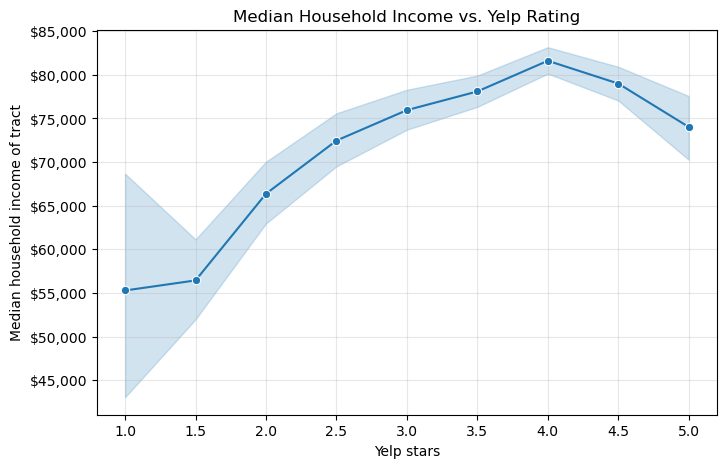

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))

# Mean income per stars category, with 95% confidence intervals
sns.lineplot(
    data=restaurants_income,
    x="stars",
    y="median_income",
    marker="o",
    ax=ax,
)

ax.set_xticks(sorted(restaurants_income["stars"].unique()))
ax.yaxis.set_major_formatter(lambda y, pos: f"${y:,.0f}")
ax.set_xlabel("Yelp stars")
ax.set_ylabel("Median household income of tract")
ax.set_title("Median Household Income vs. Yelp Rating")
ax.grid(alpha=0.3)

In [10]:
# Number of restaurants and mean income in each stars category
restaurants_income.groupby("stars")["median_income"].agg(["count", "mean"])

,count,mean
stars,,
1.0,34,55285.764706
1.5,142,56439.014085
2.0,363,66371.889807
2.5,567,72465.160494
3.0,988,75957.046559
3.5,1547,78097.409179
4.0,1912,81611.846234
4.5,1246,79001.227929
5.0,280,74027.035714


**Answer:**

Yes, there is a positive correlation between a restaurant’s Yelp rating and the median household income of its census tract, but it does not rise all the way up. Average tract income climbs steadily from about \$55,000 for 1-star restaurants to about $82,000 for 4-star restaurants. It then drops back to about \$79,000 at 4.5 stars and \$74,000 at 5 stars.

How much to trust this pattern depends on sample size. The middle categories (2.5–4.5 stars) each have several hundred to nearly two thousand restaurants, so their confidence intervals are narrow and the upward trend from 2.5 to 4 stars is fairly reliable. The low end has far fewer restaurants (34 at 1 star, 142 at 1.5 stars), so those intervals are very wide and the exact values should not be over-interpreted. The 5-star category (280 restaurants) also has a wider interval than the middle categories, so the size of the drop at the top should be read with caution.

This is a correlation, not a causal relationship: the two variables move together, but this analysis cannot tell us why. There is also an ecological fallacy issue. The income measure describes the residents of the tract, not the people writing the reviews, and in areas like Center City many reviewers are commuters and tourists rather than local residents. Finally, the observations are not independent. All restaurants in the same tract share a single income value, so tracts with many restaurants carry more weight, and the confidence intervals likely look narrower than they really are.